#**Details:**
**Name:** Siddhesh Abasaheb Mane

**PRN:** 202401040187

**Batch:** A2

**Roll No.:** 46

#**Title**
Classification Models Using the Bank Marketing Dataset

#**Aim:**
 Develop and compare SVM, Decision Tree, K-Nearest Neighbours (KNN), and Gaussian Naïve Bayes classifiers. Evaluate them using accuracy, precision, recall, F1-score, and log loss.

#**Problem:**
Predict whether a bank customer will subscribe to a term deposit (`yes` or `no`) based on demographic, contact, and campaign-related information.

#**1. Import libraries**

In [2]:

import io
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    log_loss, classification_report, confusion_matrix
)

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
print("All libraries imported successfully.")

All libraries imported successfully.


#**2. Load UCI Bank Marketing dataset**

In [3]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00222/bank.zip"

with urllib.request.urlopen(url) as response:
    zip_data = response.read()

with zipfile.ZipFile(io.BytesIO(zip_data)) as archive:
    with archive.open("bank-full.csv") as file:
        df = pd.read_csv(file, sep=";")

print("Dataset loaded successfully.")
print("Number of samples:", df.shape[0])
print("Number of features:", df.shape[1] - 1)
display(df.head())

Dataset loaded successfully.
Number of samples: 45211
Number of features: 16


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


#**3. Display target classes**

In [4]:
print("Target classes:")
print(df["y"].unique())

print("\\nClass distribution:")
print(df["y"].value_counts())

Target classes:
['no' 'yes']
\nClass distribution:
y
no     39922
yes     5289
Name: count, dtype: int64


In [5]:
# Check for missing values

print("Missing values in each column:")
print(df.isnull().sum())
print("\\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64
\nTotal missing values: 0


In [6]:
# Display statistical summary

display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


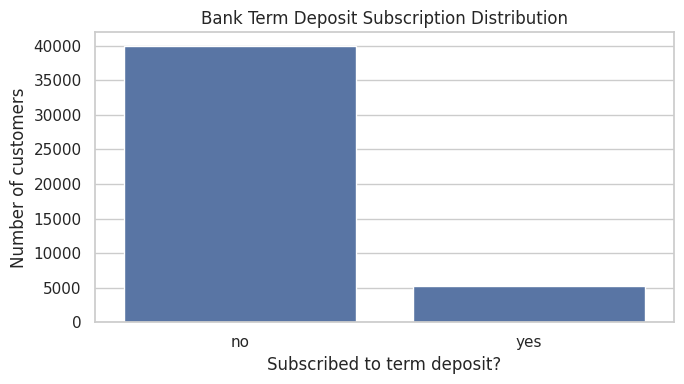

In [7]:
# Visualize target class distribution

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="y")
plt.title("Bank Term Deposit Subscription Distribution")
plt.xlabel("Subscribed to term deposit?")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

#**4. Data Preprocessing**

The target column `y` is converted into binary values:
- `no` = 0
- `yes` = 1

Categorical features are converted using One-Hot Encoding, while numerical features are standardised. A stratified train-test split preserves the target-class proportions. All transformations are fitted on training data only.

For manageable execution in Colab, this practical uses a reproducible stratified sample of 12,000 rows from the original 45,211-row dataset.

In [8]:

sample_df = df.groupby("y", group_keys=False).apply(
    lambda group: group.sample(
        n=round(12000 * len(group) / len(df)),
        random_state=RANDOM_STATE
    )
).reset_index(drop=True)

X = sample_df.drop(columns=["y"])
y = sample_df["y"].map({"no": 0, "yes": 1})

print("Sample shape:", sample_df.shape)
print("Target distribution:")
display(y.value_counts())

Sample shape: (12000, 17)
Target distribution:


/tmp/ipykernel_3075/1130718626.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sample_df = df.groupby("y", group_keys=False).apply(


,count
y,
0,10596
1,1404


In [9]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 9600
Testing samples: 2400


In [10]:
# Identify numerical and categorical columns and build preprocessing

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
    ]
)

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


#**5. Support Vector Machine (SVM)**

In [11]:
# Train SVM classifier

svm_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", SVC(
        kernel="rbf", C=1.0, gamma="scale",
        probability=True, class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

svm_model.fit(X_train, y_train)
svm_pred = svm_model.predict(X_test)
svm_prob = svm_model.predict_proba(X_test)[:, 1]
print("SVM model trained successfully.")

SVM model trained successfully.


In [12]:
# Evaluate SVM

svm_accuracy = accuracy_score(y_test, svm_pred)
svm_precision = precision_score(y_test, svm_pred, zero_division=0)
svm_recall = recall_score(y_test, svm_pred, zero_division=0)
svm_f1 = f1_score(y_test, svm_pred, zero_division=0)
svm_loss = log_loss(y_test, svm_prob)

print("SVM Performance")
print("Accuracy :", svm_accuracy)
print("Precision:", svm_precision)
print("Recall   :", svm_recall)
print("F1-score :", svm_f1)
print("Log Loss :", svm_loss)

SVM Performance
Accuracy : 0.85125
Precision: 0.4316546762589928
Recall   : 0.8540925266903915
F1-score : 0.5734767025089605
Log Loss : 0.20693493918890649


In [13]:
# SVM classification report

print(classification_report(
    y_test, svm_pred,
    target_names=["No subscription", "Subscription"],
    zero_division=0
))

                 precision    recall  f1-score   support

No subscription       0.98      0.85      0.91      2119
   Subscription       0.43      0.85      0.57       281

       accuracy                           0.85      2400
      macro avg       0.70      0.85      0.74      2400
   weighted avg       0.91      0.85      0.87      2400



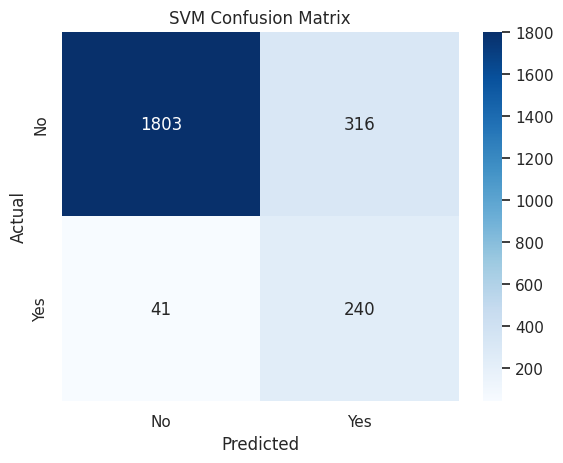

In [14]:
# SVM confusion matrix

sns.heatmap(confusion_matrix(y_test, svm_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

#**6. Decision Tree (CART)**

In [15]:
# Train Decision Tree (CART)

dt_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="gini", max_depth=8, min_samples_leaf=10,
        class_weight="balanced", random_state=RANDOM_STATE
    ))
])

dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)
dt_prob = dt_model.predict_proba(X_test)[:, 1]
print("Decision Tree trained successfully.")

Decision Tree trained successfully.


In [16]:
# Evaluate Decision Tree

dt_accuracy = accuracy_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred, zero_division=0)
dt_recall = recall_score(y_test, dt_pred, zero_division=0)
dt_f1 = f1_score(y_test, dt_pred, zero_division=0)
dt_loss = log_loss(y_test, dt_prob)

print("Decision Tree Performance")
print("Accuracy :", dt_accuracy)
print("Precision:", dt_precision)
print("Recall   :", dt_recall)
print("F1-score :", dt_f1)
print("Log Loss :", dt_loss)

Decision Tree Performance
Accuracy : 0.8141666666666667
Precision: 0.3692551505546751
Recall   : 0.8291814946619217
F1-score : 0.5109649122807017
Log Loss : 0.5518476282483061


In [17]:
# Decision Tree classification report

print(classification_report(
    y_test, dt_pred,
    target_names=["No subscription", "Subscription"],
    zero_division=0
))

                 precision    recall  f1-score   support

No subscription       0.97      0.81      0.89      2119
   Subscription       0.37      0.83      0.51       281

       accuracy                           0.81      2400
      macro avg       0.67      0.82      0.70      2400
   weighted avg       0.90      0.81      0.84      2400



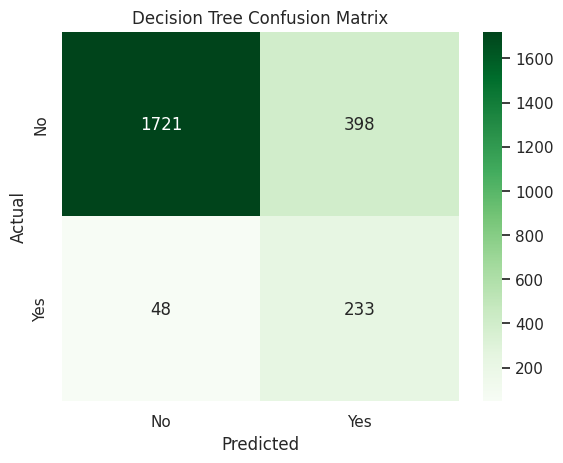

In [18]:
# Decision Tree confusion matrix

sns.heatmap(confusion_matrix(y_test, dt_pred), annot=True, fmt="d", cmap="Greens",
            xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

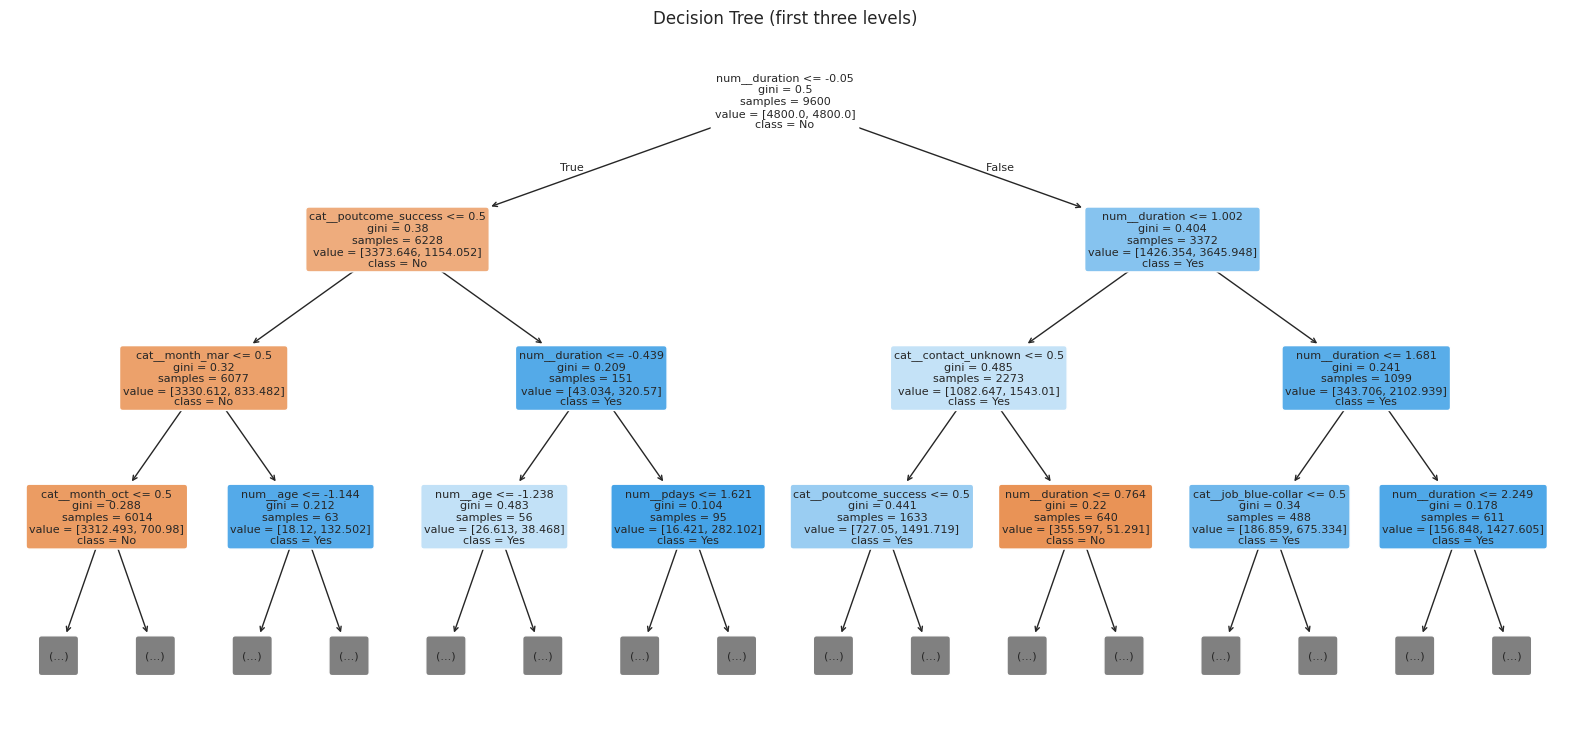

In [19]:
# Visualize the trained Decision Tree

tree_classifier = dt_model.named_steps["classifier"]
feature_names = dt_model.named_steps["preprocessing"].get_feature_names_out()

plt.figure(figsize=(20, 9))
plot_tree(tree_classifier, max_depth=3, feature_names=feature_names,
          class_names=["No", "Yes"], filled=True, rounded=True, fontsize=8)
plt.title("Decision Tree (first three levels)")
plt.show()

#**7. K-Nearest Neighbors (KNN)**

In [20]:
# Train KNN classifier

knn_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=7, weights="distance"))
])

knn_model.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)
knn_prob = knn_model.predict_proba(X_test)[:, 1]
print("KNN model trained successfully.")

KNN model trained successfully.


In [21]:
# Evaluate KNN

knn_accuracy = accuracy_score(y_test, knn_pred)
knn_precision = precision_score(y_test, knn_pred, zero_division=0)
knn_recall = recall_score(y_test, knn_pred, zero_division=0)
knn_f1 = f1_score(y_test, knn_pred, zero_division=0)
knn_loss = log_loss(y_test, knn_prob)

print("KNN Performance")
print("Accuracy :", knn_accuracy)
print("Precision:", knn_precision)
print("Recall   :", knn_recall)
print("F1-score :", knn_f1)
print("Log Loss :", knn_loss)

KNN Performance
Accuracy : 0.9025
Precision: 0.6910569105691057
Recall   : 0.302491103202847
F1-score : 0.4207920792079208
Log Loss : 0.9494420288410701


In [22]:
# KNN classification report

print(classification_report(
    y_test, knn_pred,
    target_names=["No subscription", "Subscription"],
    zero_division=0
))

                 precision    recall  f1-score   support

No subscription       0.91      0.98      0.95      2119
   Subscription       0.69      0.30      0.42       281

       accuracy                           0.90      2400
      macro avg       0.80      0.64      0.68      2400
   weighted avg       0.89      0.90      0.89      2400



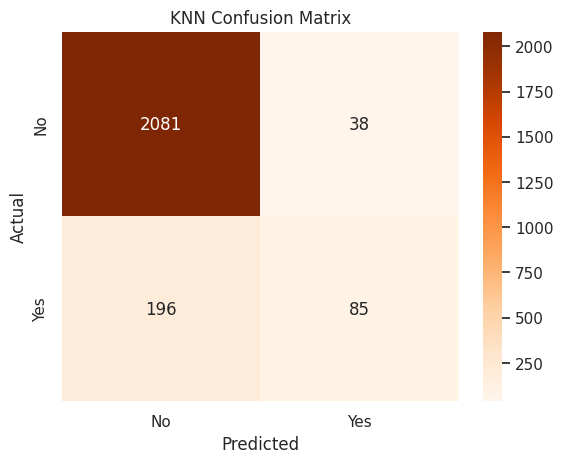

In [23]:
# KNN confusion matrix

sns.heatmap(confusion_matrix(y_test, knn_pred), annot=True, fmt="d", cmap="Oranges",
            xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

#**8. Naïve Bayes**

In [24]:
# Train Gaussian Naïve Bayes classifier

nb_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", GaussianNB())
])

nb_model.fit(X_train, y_train)
nb_pred = nb_model.predict(X_test)
nb_prob = nb_model.predict_proba(X_test)[:, 1]
print("Gaussian Naïve Bayes trained successfully.")

Gaussian Naïve Bayes trained successfully.


In [25]:
# Evaluate Naïve Bayes

nb_accuracy = accuracy_score(y_test, nb_pred)
nb_precision = precision_score(y_test, nb_pred, zero_division=0)
nb_recall = recall_score(y_test, nb_pred, zero_division=0)
nb_f1 = f1_score(y_test, nb_pred, zero_division=0)
nb_loss = log_loss(y_test, nb_prob)

print("Gaussian Naïve Bayes Performance")
print("Accuracy :", nb_accuracy)
print("Precision:", nb_precision)
print("Recall   :", nb_recall)
print("F1-score :", nb_f1)
print("Log Loss :", nb_loss)

Gaussian Naïve Bayes Performance
Accuracy : 0.835
Precision: 0.35443037974683544
Recall   : 0.498220640569395
F1-score : 0.41420118343195267
Log Loss : 1.8769791314909328


In [26]:
# Naïve Bayes classification report

print(classification_report(
    y_test, nb_pred,
    target_names=["No subscription", "Subscription"],
    zero_division=0
))

                 precision    recall  f1-score   support

No subscription       0.93      0.88      0.90      2119
   Subscription       0.35      0.50      0.41       281

       accuracy                           0.83      2400
      macro avg       0.64      0.69      0.66      2400
   weighted avg       0.86      0.83      0.85      2400



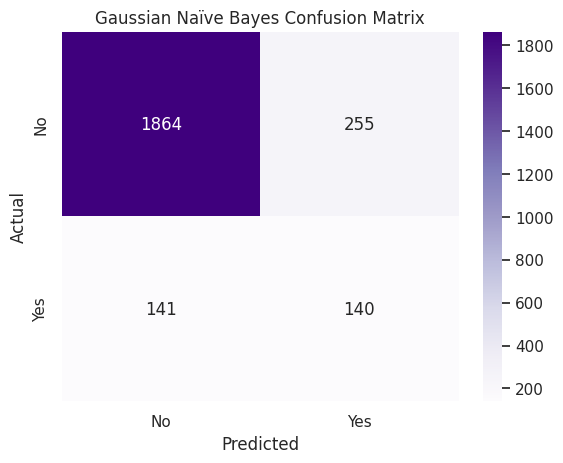

In [27]:
# Naïve Bayes confusion matrix

sns.heatmap(confusion_matrix(y_test, nb_pred), annot=True, fmt="d", cmap="Purples",
            xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
plt.title("Gaussian Naïve Bayes Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

#**9. Comparative Performance Analysis**

In [28]:
# Create a comparison table for all four models

comparison = pd.DataFrame({
    "Model": ["SVM", "Decision Tree", "KNN", "Naïve Bayes"],
    "Accuracy": [svm_accuracy, dt_accuracy, knn_accuracy, nb_accuracy],
    "Precision": [svm_precision, dt_precision, knn_precision, nb_precision],
    "Recall": [svm_recall, dt_recall, knn_recall, nb_recall],
    "F1-score": [svm_f1, dt_f1, knn_f1, nb_f1],
    "Log Loss": [svm_loss, dt_loss, knn_loss, nb_loss]
}).set_index("Model")

display(comparison.round(4))

,Accuracy,Precision,Recall,F1-score,Log Loss
Model,,,,,
SVM,0.8512,0.4317,0.8541,0.5735,0.2069
Decision Tree,0.8142,0.3693,0.8292,0.5110,0.5518
KNN,0.9025,0.6911,0.3025,0.4208,0.9494
Naïve Bayes,0.8350,0.3544,0.4982,0.4142,1.8770


In [29]:
# Identify the best-performing model for each metric

print("Highest Accuracy :", comparison["Accuracy"].idxmax())
print("Highest Precision:", comparison["Precision"].idxmax())
print("Highest Recall   :", comparison["Recall"].idxmax())
print("Highest F1-score :", comparison["F1-score"].idxmax())
print("Lowest Log Loss  :", comparison["Log Loss"].idxmin())

Highest Accuracy : KNN
Highest Precision: KNN
Highest Recall   : SVM
Highest F1-score : SVM
Lowest Log Loss  : SVM


#**10. Performance Comparison Visualization**

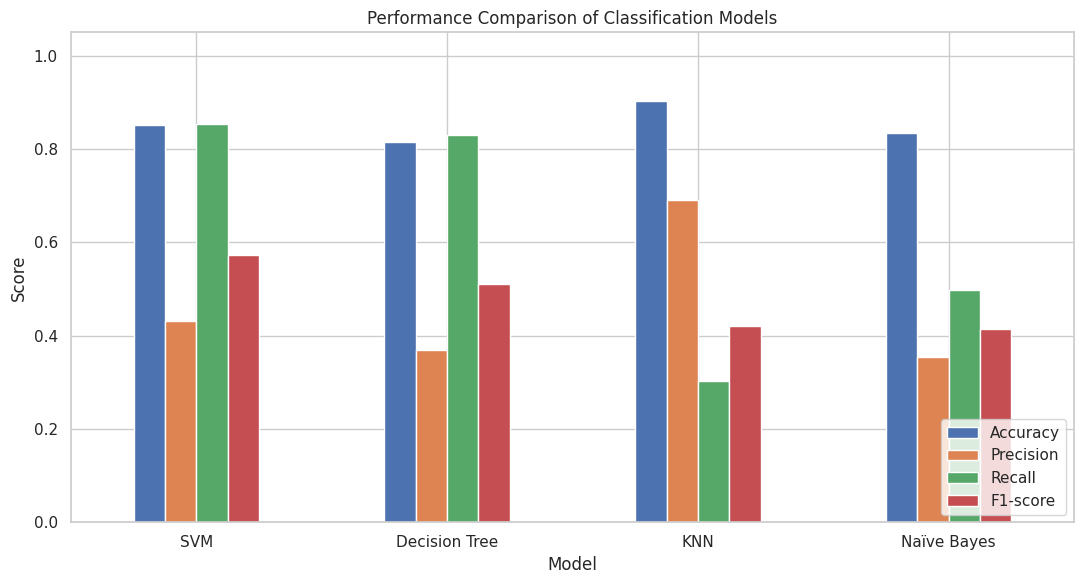

In [30]:
# Compare Accuracy, Precision, Recall and F1-score

comparison[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(11, 6), ylim=(0, 1.05)
)
plt.title("Performance Comparison of Classification Models")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

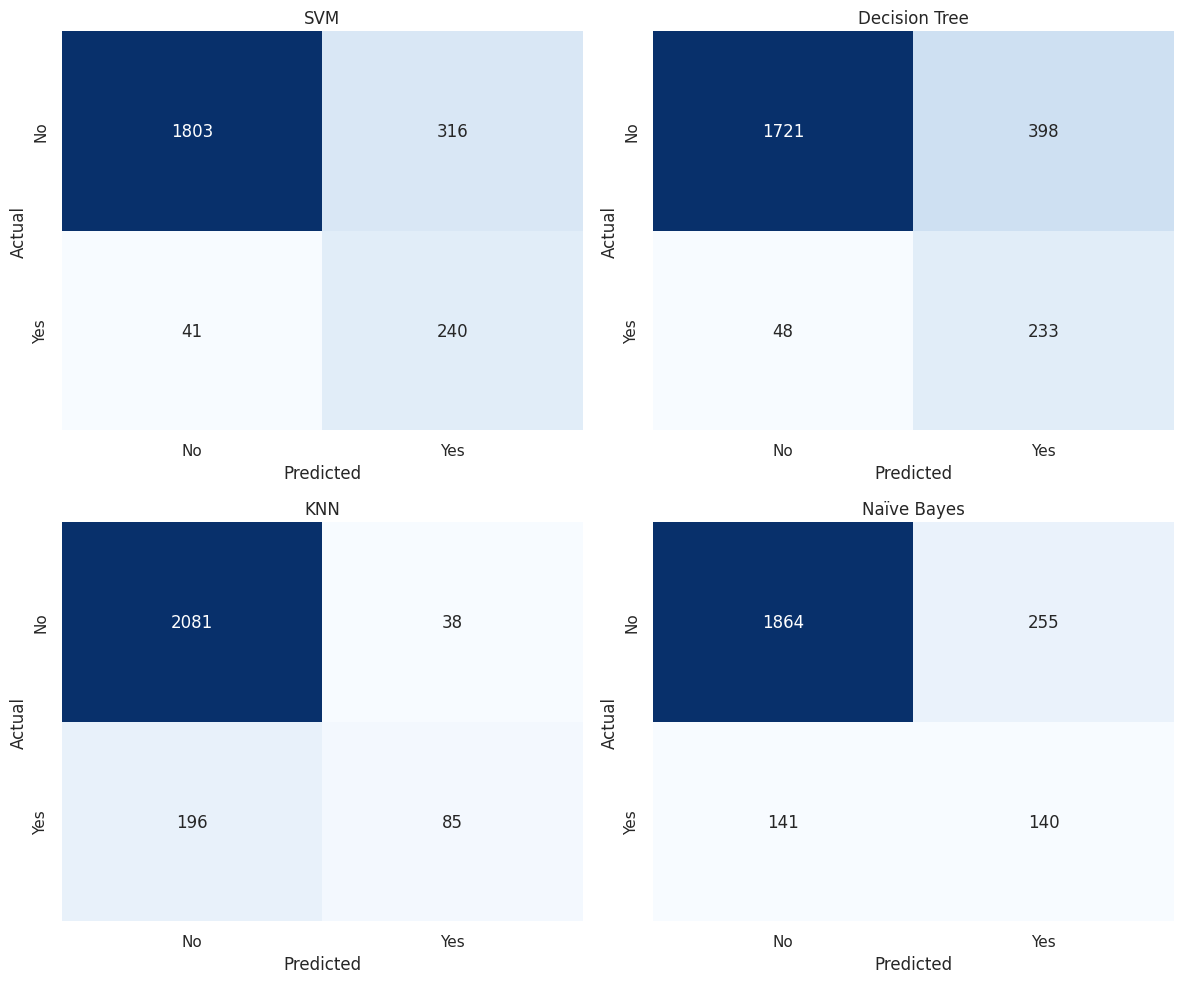

In [31]:
# Combined confusion matrices

predictions = {
    "SVM": svm_pred,
    "Decision Tree": dt_pred,
    "KNN": knn_pred,
    "Naïve Bayes": nb_pred
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (name, pred) in zip(axes.ravel(), predictions.items()):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d",
                cmap="Blues", cbar=False,
                xticklabels=["No", "Yes"], yticklabels=["No", "Yes"], ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

#**11. Critical Analysis and Comparative Findings**

The comparative analysis of SVM, Decision Tree, KNN, and Naïve Bayes reveals that each algorithm has different strengths and limitations when predicting bank term-deposit subscriptions.

1. Support Vector Machine (SVM): SVM achieved the highest recall of 85.41%, F1-score of 57.35%, and the lowest log loss of 0.2069. It correctly identified 240 out of 281 actual subscribers. This makes SVM suitable when identifying as many potential subscribers as possible is important.

2. Decision Tree (CART): Decision Tree achieved an accuracy of 81.42% and recall of 82.92%. It correctly identified 233 actual subscribers. Its tree-based structure makes it easier to understand and interpret, although it may overfit if its depth is not controlled.

3. K-Nearest Neighbors (KNN): KNN achieved the highest accuracy of 90.25% and precision of 69.11%. However, its recall was only 30.25%, meaning it identified just 85 out of 281 actual subscribers. Therefore, despite its high accuracy, it missed many potential subscribers. This demonstrates why accuracy alone is not sufficient for evaluating an imbalanced classification problem.

4. Naïve Bayes: Naïve Bayes achieved an accuracy of 83.50%, but its F1-score was 41.42% and log loss was 1.8770, the highest among the four models. This indicates comparatively weaker positive-class detection and probability prediction in this experiment.

#**Conclusion**
The practical successfully implemented and compared four classification algorithms: Support Vector Machine (SVM), Decision Tree (CART), K-Nearest Neighbors (KNN), and Gaussian Naïve Bayes using the Bank Marketing dataset to predict whether a customer would subscribe to a term deposit.

The models were evaluated using accuracy, precision, recall, F1-score, and log loss. Among the four models, KNN achieved the highest accuracy of 90.25% and precision of 69.11%, while SVM achieved the highest recall of 85.41%, highest F1-score of 57.35%, and lowest log loss of 0.2069.

The results demonstrate that high accuracy does not always indicate the best classification performance, especially when the dataset has imbalanced classes. KNN missed many actual subscribers, whereas SVM provided a better balance between precision and recall. Therefore, SVM was found to be the more suitable model for identifying potential subscribers in this experiment.

Overall, this practical helped me understand the working of different classification algorithms, evaluate their performance using multiple metrics, interpret confusion matrices, and perform comparative analysis to select an appropriate machine learning model for a real-world classification problem.

#**Github Link**
[click here](https://github.com/siddheshmane18/AIML_SEM5/tree/main/Continuous%20Assessment)

#**Colab Link**
[click here](https://colab.research.google.com/drive/1ap7nnanDwIY2nMWuvKNadIlJrqVA1czl?usp=drive_link)